In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df = pd.read_excel("Sample_Superstore_Cleaned.xlsx")

df["Order Date"] = pd.to_datetime(df["Order Date"])

print(df.head())

   Row ID        Order ID Order Date  Ship Date       Ship Mode Customer ID  \
0       1  US-2023-103800 2023-01-03 2023-01-07  Standard Class    DP-13000   
1       2  US-2023-112326 2023-01-04 2023-01-08  Standard Class    PO-19195   
2       3  US-2023-112326 2023-01-04 2023-01-08  Standard Class    PO-19195   
3       4  US-2023-112326 2023-01-04 2023-01-08  Standard Class    PO-19195   
4       5  US-2023-141817 2023-01-05 2023-01-12  Standard Class    MB-18085   

   Customer Name      Segment Country/Region          City  ... Postal Code  \
0  Darren Powers     Consumer  United States       Houston  ...       77095   
1  Phillina Ober  Home Office  United States    Naperville  ...       60540   
2  Phillina Ober  Home Office  United States    Naperville  ...       60540   
3  Phillina Ober  Home Office  United States    Naperville  ...       60540   
4     Mick Brown     Consumer  United States  Philadelphia  ...       19143   

    Region       Product ID         Category Sub-C

In [3]:
total_sales = df["Sales"].sum()
total_profit = df["Profit"].sum()

profit_margin = (total_profit / total_sales) * 100

print("Total Sales:", round(total_sales, 2))
print("Total Profit:", round(total_profit, 2))
print("Overall Profit Margin:", round(profit_margin, 2), "%")

Total Sales: 2326534.35
Total Profit: 292296.81
Overall Profit Margin: 12.56 %


In [4]:
df["Year"] = df["Order Date"].dt.year

yearly = df.groupby("Year").agg(
    Revenue=("Sales", "sum"),
    Profit=("Profit", "sum")
).reset_index()

yearly["Profit Margin"] = (
    yearly["Profit"] / yearly["Revenue"]
) * 100

yearly["Revenue Growth"] = (
    yearly["Revenue"].pct_change() * 100
)

display(yearly.round(2))

,Year,Revenue,Profit,Profit Margin,Revenue Growth
0,2023,494040.21,51684.30,10.46,NaN
1,2024,472993.03,62020.97,13.11,-4.26
2,2025,613933.58,82665.20,13.46,29.80
3,2026,745567.53,95926.35,12.87,21.44


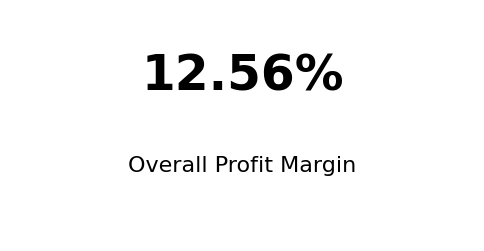

In [5]:
plt.figure(figsize=(6, 3))

plt.text(
    0.5, 0.65,
    f"{profit_margin:.2f}%",
    fontsize=35,
    fontweight="bold",
    ha="center"
)

plt.text(
    0.5, 0.30,
    "Overall Profit Margin",
    fontsize=16,
    ha="center"
)

plt.axis("off")
plt.savefig("01_Profit_Margin_KPI.png",
            dpi=300, bbox_inches="tight")
plt.show()

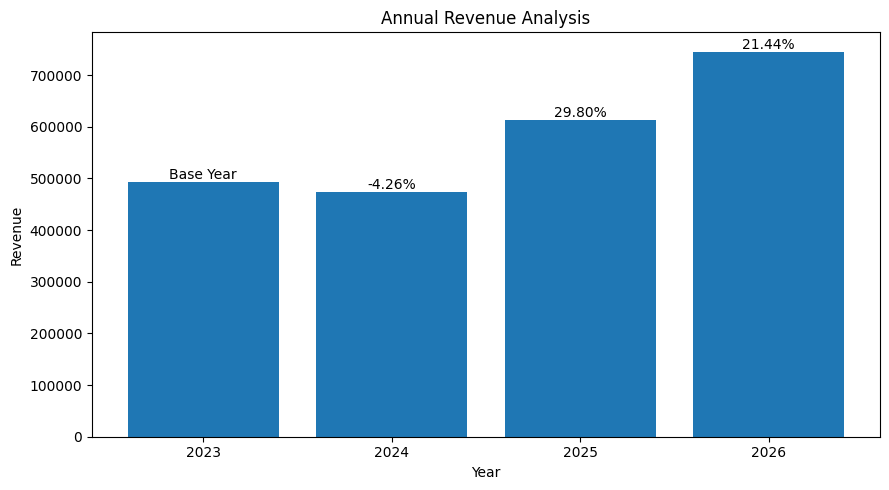

In [6]:
plt.figure(figsize=(9, 5))

plt.bar(
    yearly["Year"].astype(str),
    yearly["Revenue"]
)

plt.title("Annual Revenue Analysis")
plt.xlabel("Year")
plt.ylabel("Revenue")

for i, row in yearly.iterrows():
    growth = row["Revenue Growth"]

    label = "Base Year" if pd.isna(growth) else f"{growth:.2f}%"

    plt.text(
        i, row["Revenue"],
        label,
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.savefig("02_Annual_Revenue_Growth.png", dpi=300)
plt.show()

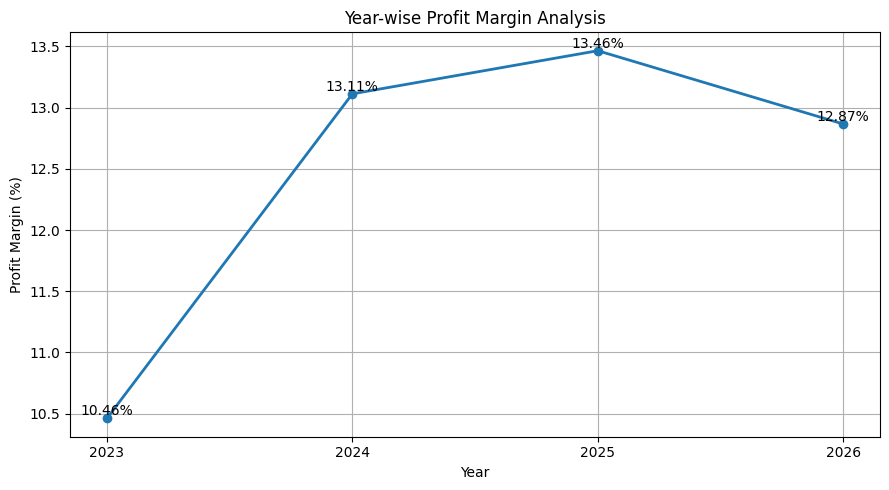

In [7]:
plt.figure(figsize=(9, 5))

plt.plot(
    yearly["Year"],
    yearly["Profit Margin"],
    marker="o",
    linewidth=2
)

plt.title("Year-wise Profit Margin Analysis")
plt.xlabel("Year")
plt.ylabel("Profit Margin (%)")
plt.xticks(yearly["Year"])

for x, y in zip(yearly["Year"], yearly["Profit Margin"]):
    plt.text(x, y, f"{y:.2f}%", ha="center", va="bottom")

plt.grid(True)
plt.tight_layout()

plt.savefig("03_Yearly_Profit_Margin.png", dpi=300)
plt.show()

In [8]:
yearly.to_excel(
    "Yearly_Profit_Revenue_Analysis.xlsx",
    index=False
)

print("All visualizations generated successfully!")

All visualizations generated successfully!
